In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import pandas as pd

file_path = "/kaggle/input/datasets/yamsp123/cosmetics-brand-dataset/Cosmetics_Brand_Business_Comparison_Dataset.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Brand Dataset"
)

df.head()

,Brand,Category,Revenue Reference,Sales Reference,Gross/Net Profit Reference,Revenue Growth Reference,Customer Reviews / Rating,Key Features,Quality Score /10,Customer Review Score /10,Feature Score /10,Product Range Score /10
0,Mamaearth,Skincare & Haircare,"₹1,000–₹1,500 Cr","₹1,000–₹1,500 Cr",₹100–₹200 Cr,8–12%,4.3/5,"Natural-positioning, ingredient-led products, ...",8.5,9,8.0,7.5
1,Lakmé,Makeup & Skincare,"₹2,000–₹3,000 Cr","₹2,000–₹3,000 Cr",₹300–₹500 Cr,5–8%,4.4/5,"Makeup, skincare, salon ecosystem, broad retai...",9.0,9,9.0,9.0
2,NIVEA,Skincare & Bodycare,"₹45,000+ Cr*","₹45,000+ Cr*","₹6,000+ Cr*",~1%*,4.5/5,"Skin science, moisturization, bodycare, sun care",9.0,9,9.0,10.0
3,Maybelline,Makeup,"₹1,500–₹2,500 Cr","₹1,500–₹2,500 Cr",₹200–₹400 Cr,5–10%,4.4/5,"Mass-market makeup, trend-focused launches, st...",9.0,9,9.0,9.0
4,SUGAR Cosmetics,Makeup,₹400–₹450 Cr,₹400–₹450 Cr,Loss-making / not consistently disclosed,NaN,4.3/5,"India-focused makeup, bold shades, digital-fir...",8.0,8,9.0,8.0


In [3]:
df["Revenue (Cr)"] = [1250, 2500, 45000, 2000, 425, 10000, 1500, 2500, 30000, 2500, 200]

df[["Brand", "Revenue (Cr)"]]

,Brand,Revenue (Cr)
0,Mamaearth,1250
1,Lakmé,2500
2,NIVEA,45000
3,Maybelline,2000
4,SUGAR Cosmetics,425
5,L'Oréal Paris,10000
6,Nykaa Cosmetics,1500
7,Himalaya,2500
8,RENEE,30000
9,MARS Cosmetics,2500


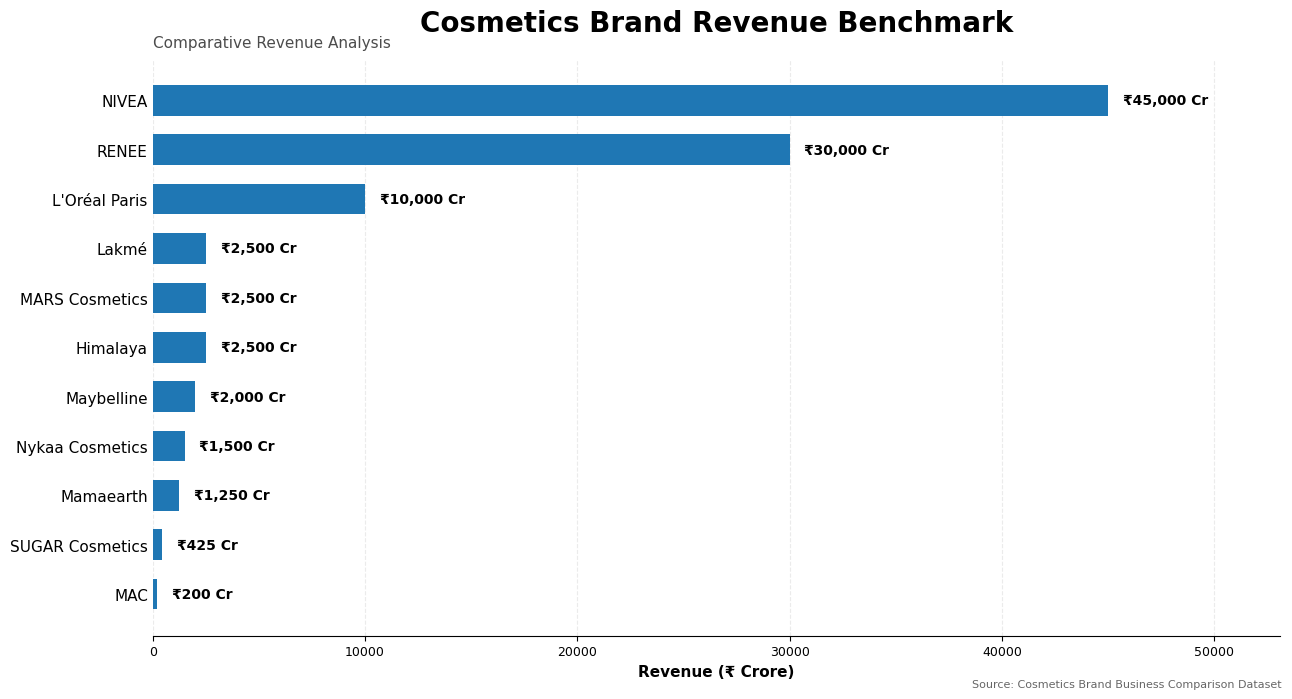

In [4]:
import matplotlib.pyplot as plt

# Highest revenue on top
business_df = df.sort_values("Revenue (Cr)", ascending=True)

# Create professional chart
fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    business_df["Brand"],
    business_df["Revenue (Cr)"],
    height=0.62
)

# Add values at the end of each bar
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + 700,
        bar.get_y() + bar.get_height() / 2,
        f"₹{value:,.0f} Cr",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Title
ax.set_title(
    "Cosmetics Brand Revenue Benchmark",
    fontsize=20,
    fontweight="bold",
    pad=20
)

# Subtitle
ax.text(
    0,
    1.02,
    "Comparative Revenue Analysis",
    transform=ax.transAxes,
    fontsize=11,
    alpha=0.7
)

# Axis
ax.set_xlabel(
    "Revenue (₹ Crore)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

# Grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Clean labels
ax.tick_params(axis="y", labelsize=11, length=0)
ax.tick_params(axis="x", labelsize=9)

# Space for value labels
ax.set_xlim(
    0,
    business_df["Revenue (Cr)"].max() * 1.18
)

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.6
)

plt.tight_layout()
plt.show()

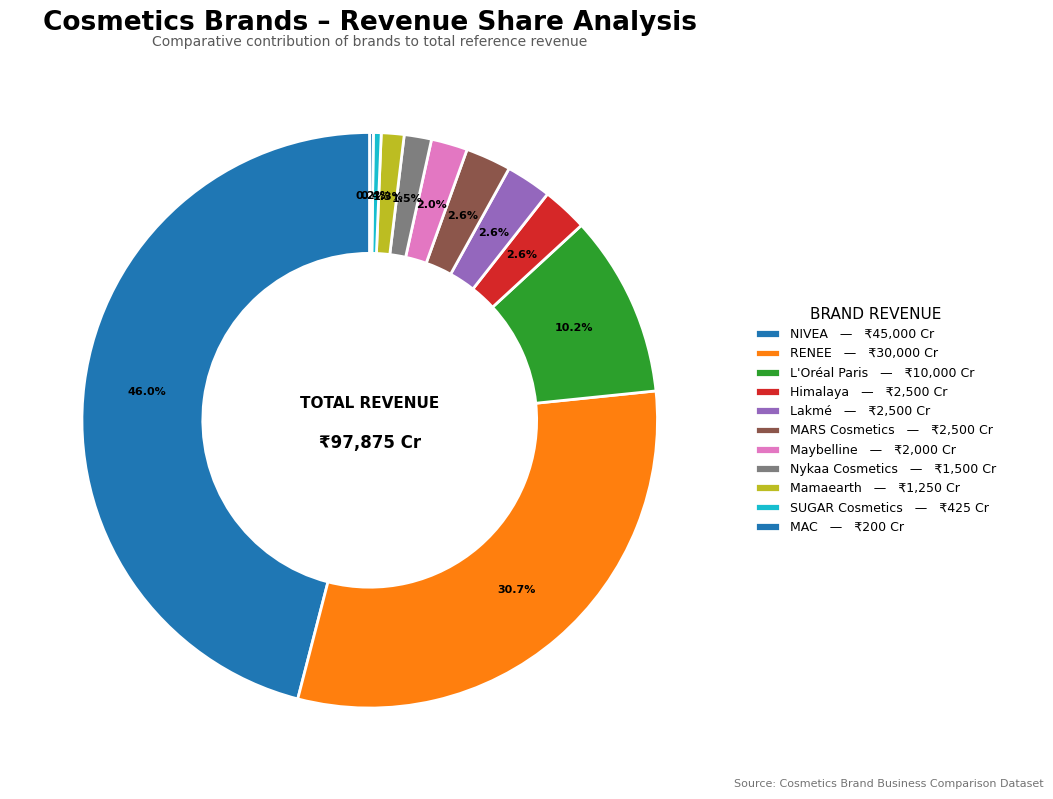

In [7]:
import matplotlib.pyplot as plt

# Sort revenue from highest to lowest
pie_df = df.sort_values("Revenue (Cr)", ascending=False).reset_index(drop=True)

# Figure
fig, ax = plt.subplots(figsize=(13, 8))

# Donut chart
wedges, texts, autotexts = ax.pie(
    pie_df["Revenue (Cr)"],
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": "white",
        "linewidth": 2
    }
)

# Percentage formatting
for text in autotexts:
    text.set_fontsize(8)
    text.set_fontweight("bold")

# Center information
total_revenue = pie_df["Revenue (Cr)"].sum()

ax.text(
    0, 0.06,
    "TOTAL REVENUE",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    0, -0.08,
    f"₹{total_revenue:,.0f} Cr",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

# Clean legend on the right
legend_labels = [
    f"{brand}   —   ₹{revenue:,.0f} Cr"
    for brand, revenue in zip(
        pie_df["Brand"],
        pie_df["Revenue (Cr)"]
    )
]

ax.legend(
    wedges,
    legend_labels,
    title="BRAND REVENUE",
    title_fontsize=11,
    fontsize=9,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

# Main title
plt.title(
    "Cosmetics Brands – Revenue Share Analysis",
    fontsize=19,
    fontweight="bold",
    pad=22
)

# Subtitle
plt.text(
    0.5,
    1.02,
    "Comparative contribution of brands to total reference revenue",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    alpha=0.65
)

# Remove axes
ax.set_aspect("equal")

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.55
)

plt.tight_layout()
plt.show()

In [8]:
df["Revenue Growth (%)"] = [10, 6.5, 1, 7.5, 0, 7.5, 5, 7.5, 15, 15, 2.5]

df[["Brand", "Revenue Growth (%)"]]

,Brand,Revenue Growth (%)
0,Mamaearth,10.0
1,Lakmé,6.5
2,NIVEA,1.0
3,Maybelline,7.5
4,SUGAR Cosmetics,0.0
5,L'Oréal Paris,7.5
6,Nykaa Cosmetics,5.0
7,Himalaya,7.5
8,RENEE,15.0
9,MARS Cosmetics,15.0


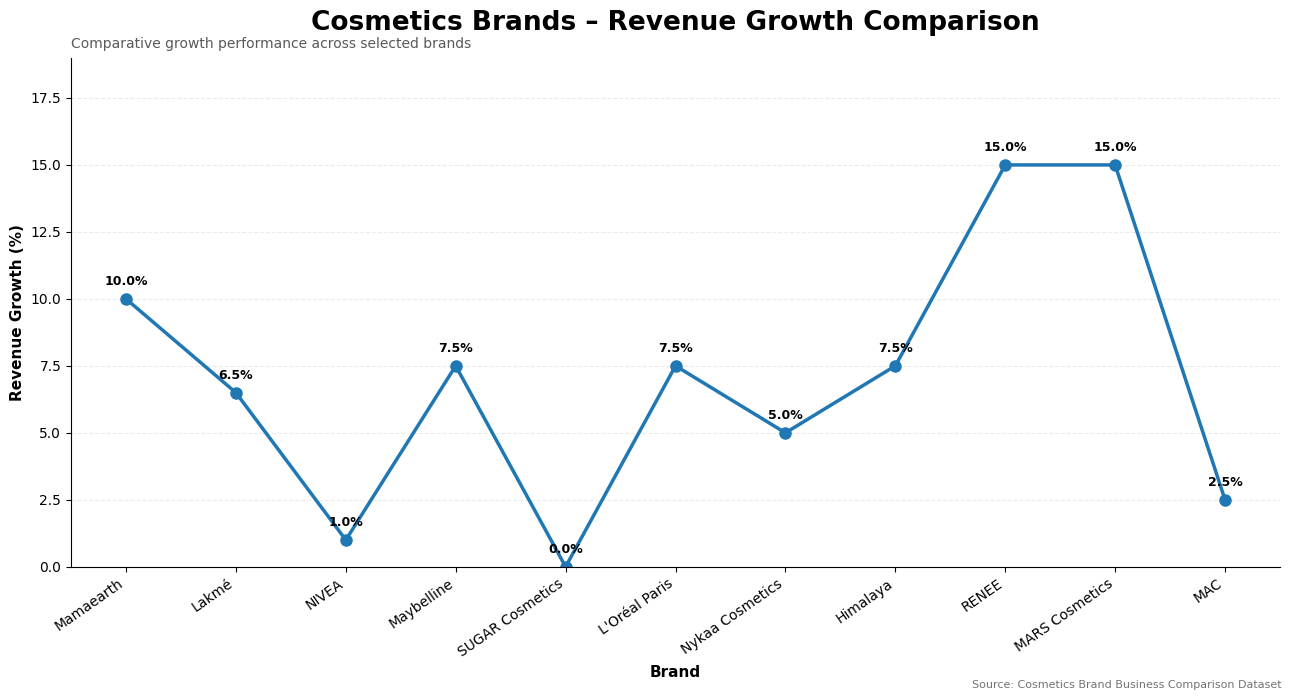

In [9]:
import matplotlib.pyplot as plt

# Keep original brand order
growth_df = df[["Brand", "Revenue Growth (%)"]].copy()

# Create figure
fig, ax = plt.subplots(figsize=(13, 7))

# Line
ax.plot(
    growth_df["Brand"],
    growth_df["Revenue Growth (%)"],
    marker="o",
    markersize=8,
    linewidth=2.5
)

# Add value labels
for i, value in enumerate(growth_df["Revenue Growth (%)"]):
    ax.annotate(
        f"{value:.1f}%",
        (i, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Title
ax.set_title(
    "Cosmetics Brands – Revenue Growth Comparison",
    fontsize=19,
    fontweight="bold",
    pad=20
)

# Subtitle
ax.text(
    0,
    1.02,
    "Comparative growth performance across selected brands",
    transform=ax.transAxes,
    fontsize=10,
    alpha=0.65
)

# Axis labels
ax.set_xlabel(
    "Brand",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Revenue Growth (%)",
    fontsize=11,
    fontweight="bold"
)

# X-axis labels
plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Start y-axis from zero
ax.set_ylim(
    0,
    growth_df["Revenue Growth (%)"].max() + 4
)

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.55
)

plt.tight_layout()
plt.show()

In [10]:
df["Profit (Cr)"] = [150, 400, 6000, 300, 0, 1000, 300, 300, 100, 100, 3000]

df[["Brand", "Profit (Cr)"]]

,Brand,Profit (Cr)
0,Mamaearth,150
1,Lakmé,400
2,NIVEA,6000
3,Maybelline,300
4,SUGAR Cosmetics,0
5,L'Oréal Paris,1000
6,Nykaa Cosmetics,300
7,Himalaya,300
8,RENEE,100
9,MARS Cosmetics,100


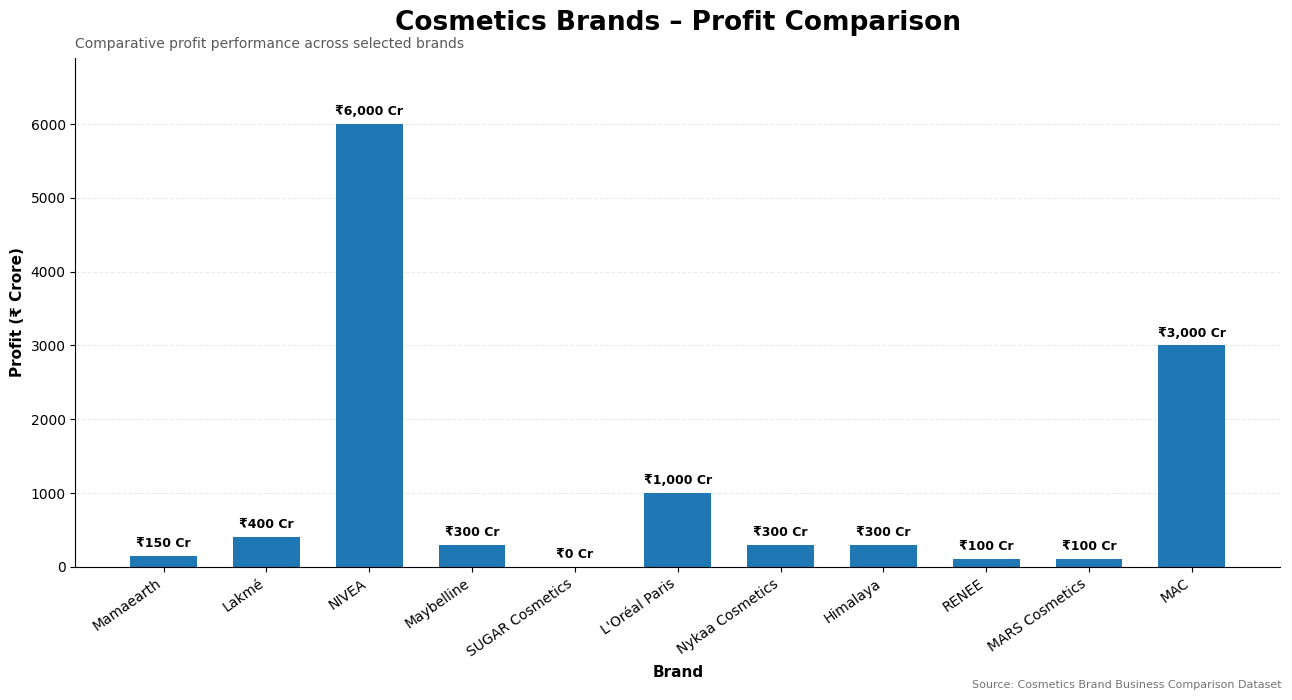

In [11]:
import matplotlib.pyplot as plt

# Keep original brand order
profit_df = df[["Brand", "Profit (Cr)"]].copy()

# Create figure
fig, ax = plt.subplots(figsize=(13, 7))

# Column chart
bars = ax.bar(
    profit_df["Brand"],
    profit_df["Profit (Cr)"],
    width=0.65
)

# Add profit values on top of columns
for bar, value in zip(bars, profit_df["Profit (Cr)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 80,
        f"₹{value:,.0f} Cr",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Title
ax.set_title(
    "Cosmetics Brands – Profit Comparison",
    fontsize=19,
    fontweight="bold",
    pad=20
)

# Subtitle
ax.text(
    0,
    1.02,
    "Comparative profit performance across selected brands",
    transform=ax.transAxes,
    fontsize=10,
    alpha=0.65
)

# Axis labels
ax.set_xlabel(
    "Brand",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Profit (₹ Crore)",
    fontsize=11,
    fontweight="bold"
)

# Rotate brand names
plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Give space for labels
ax.set_ylim(
    0,
    profit_df["Profit (Cr)"].max() * 1.15
)

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.55
)

plt.tight_layout()
plt.show()

In [12]:
df[["Brand", "Quality Score /10", "Customer Review Score /10"]]

,Brand,Quality Score /10,Customer Review Score /10
0,Mamaearth,8.5,9
1,Lakmé,9.0,9
2,NIVEA,9.0,9
3,Maybelline,9.0,9
4,SUGAR Cosmetics,8.0,8
5,L'Oréal Paris,10.0,10
6,Nykaa Cosmetics,8.5,9
7,Himalaya,9.0,9
8,RENEE,7.5,8
9,MARS Cosmetics,7.5,8


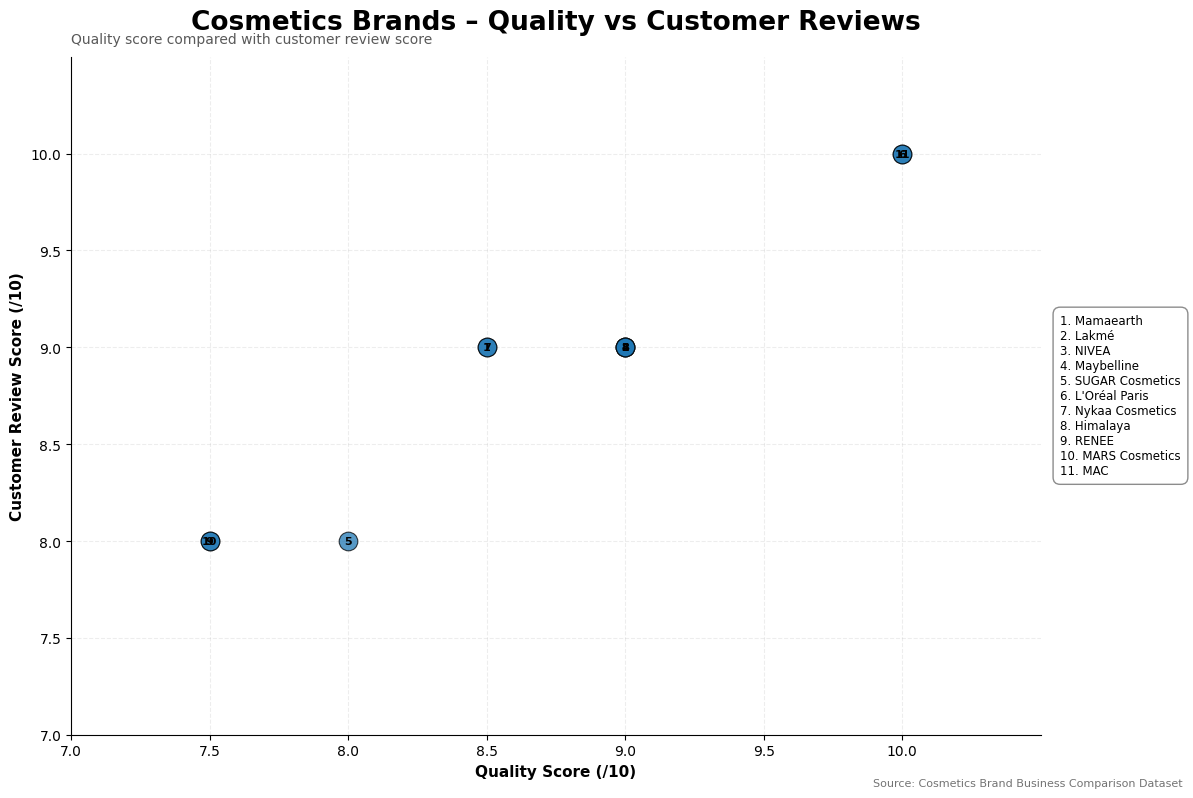

In [15]:
import matplotlib.pyplot as plt

# Required data
scatter_df = df[
    ["Brand", "Quality Score /10", "Customer Review Score /10"]
].copy()

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Scatter plot
ax.scatter(
    scatter_df["Quality Score /10"],
    scatter_df["Customer Review Score /10"],
    s=180,
    alpha=0.75,
    edgecolors="black",
    linewidths=0.8
)

# Add point numbers instead of long brand names
for i, row in scatter_df.iterrows():
    ax.annotate(
        str(i + 1),
        (
            row["Quality Score /10"],
            row["Customer Review Score /10"]
        ),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

# Title
ax.set_title(
    "Cosmetics Brands – Quality vs Customer Reviews",
    fontsize=19,
    fontweight="bold",
    pad=20
)

# Subtitle
ax.text(
    0,
    1.02,
    "Quality score compared with customer review score",
    transform=ax.transAxes,
    fontsize=10,
    alpha=0.65
)

# Axis labels
ax.set_xlabel(
    "Quality Score (/10)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Customer Review Score (/10)",
    fontsize=11,
    fontweight="bold"
)

# Score range
ax.set_xlim(7, 10.5)
ax.set_ylim(7, 10.5)

# Ticks
ax.set_xticks([7, 7.5, 8, 8.5, 9, 9.5, 10])
ax.set_yticks([7, 7.5, 8, 8.5, 9, 9.5, 10])

# Grid
ax.grid(
    linestyle="--",
    alpha=0.22
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Brand reference box
brand_text = "\n".join(
    [
        f"{i+1}. {brand}"
        for i, brand in enumerate(scatter_df["Brand"])
    ]
)

ax.text(
    1.02,
    0.5,
    brand_text,
    transform=ax.transAxes,
    fontsize=8.5,
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.55
)

plt.tight_layout()
plt.show()

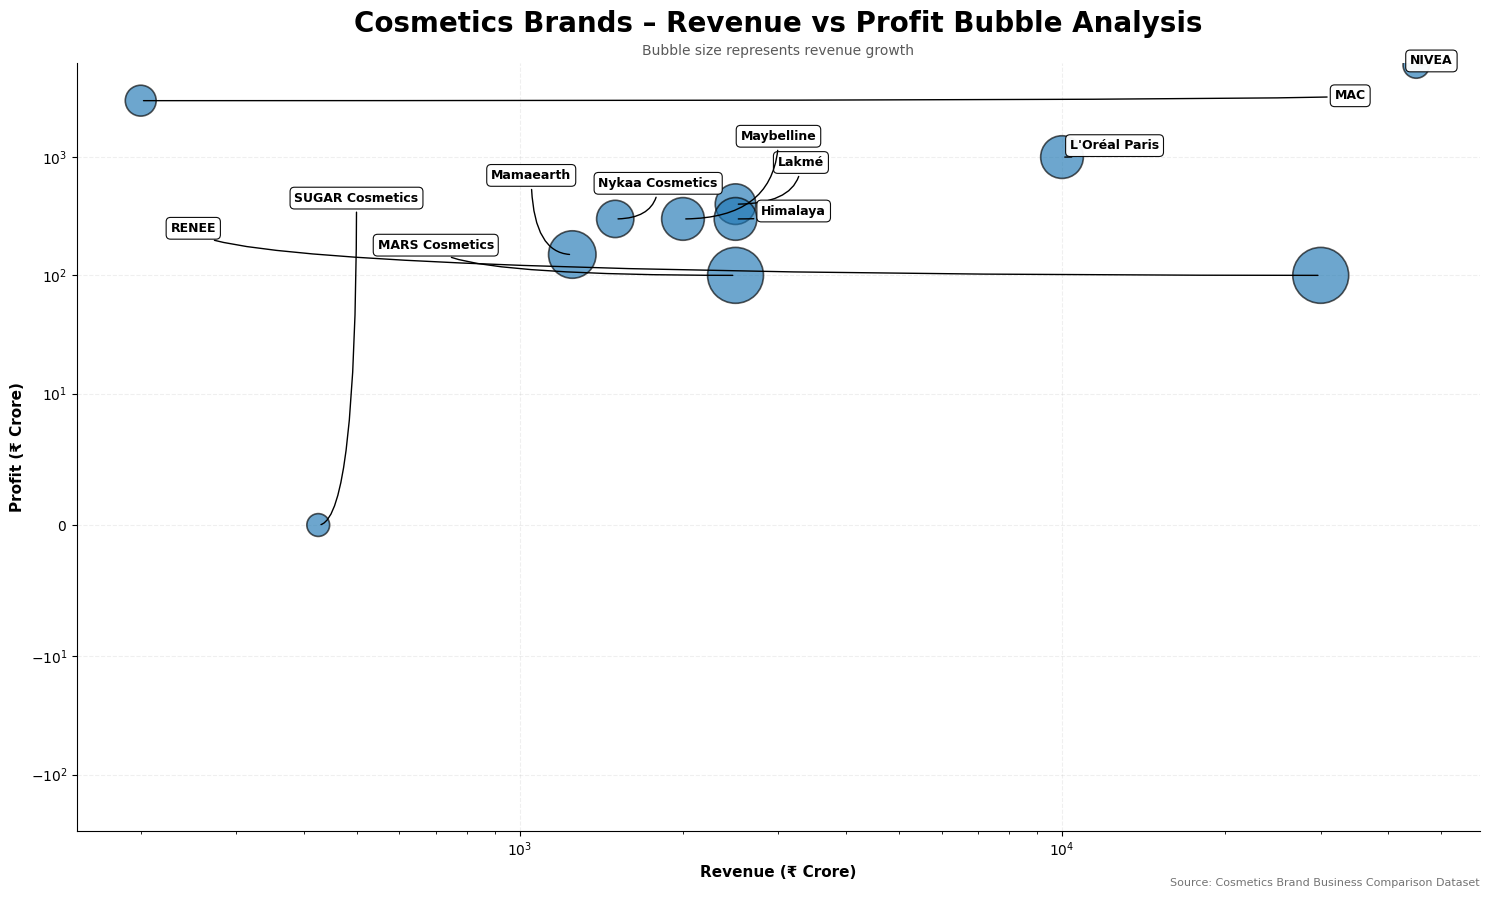

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Prepare data
# -----------------------------
bubble_df = df[
    ["Brand", "Revenue (Cr)", "Profit (Cr)", "Revenue Growth (%)"]
].copy().reset_index(drop=True)

# -----------------------------
# Create figure
# -----------------------------
fig, ax = plt.subplots(figsize=(15, 9))

# Bubble sizes
sizes = (bubble_df["Revenue Growth (%)"] + 3) * 90

# -----------------------------
# Bubble chart
# -----------------------------
ax.scatter(
    bubble_df["Revenue (Cr)"],
    bubble_df["Profit (Cr)"],
    s=sizes,
    alpha=0.65,
    edgecolors="black",
    linewidth=1.2
)

# -----------------------------
# Separate label positions
# Manually arranged for clean look
# -----------------------------
label_positions = [
    (1050, 700),       # Mamaearth
    (3300, 900),       # Lakmé
    (48000, 6500),     # NIVEA
    (3000, 1500),      # Maybelline
    (500, 450),        # SUGAR
    (12500, 1250),     # L'Oréal
    (1800, 600),       # Nykaa
    (3200, 350),       # Himalaya
    (250, 250),        # RENEE
    (700, 180),        # MARS
    (34000, 3300)      # MAC
]

# -----------------------------
# Add clean callout labels
# -----------------------------
for i, row in bubble_df.iterrows():

    x = row["Revenue (Cr)"]
    y = row["Profit (Cr)"]

    lx, ly = label_positions[i]

    ax.annotate(
        row["Brand"],
        xy=(x, y),
        xytext=(lx, ly),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
            alpha=0.95
        ),
        arrowprops=dict(
            arrowstyle="-",
            linewidth=1,
            connectionstyle="angle3"
        )
    )

# -----------------------------
# Title
# -----------------------------
ax.set_title(
    "Cosmetics Brands – Revenue vs Profit Bubble Analysis",
    fontsize=20,
    fontweight="bold",
    pad=22
)

# Subtitle
ax.text(
    0.5,
    1.01,
    "Bubble size represents revenue growth",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    alpha=0.65
)

# -----------------------------
# Axis labels
# -----------------------------
ax.set_xlabel(
    "Revenue (₹ Crore)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Profit (₹ Crore)",
    fontsize=11,
    fontweight="bold"
)

# Log scale
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=10)

# Grid
ax.grid(
    linestyle="--",
    alpha=0.20
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Footer
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    alpha=0.55
)

plt.tight_layout()
plt.show()

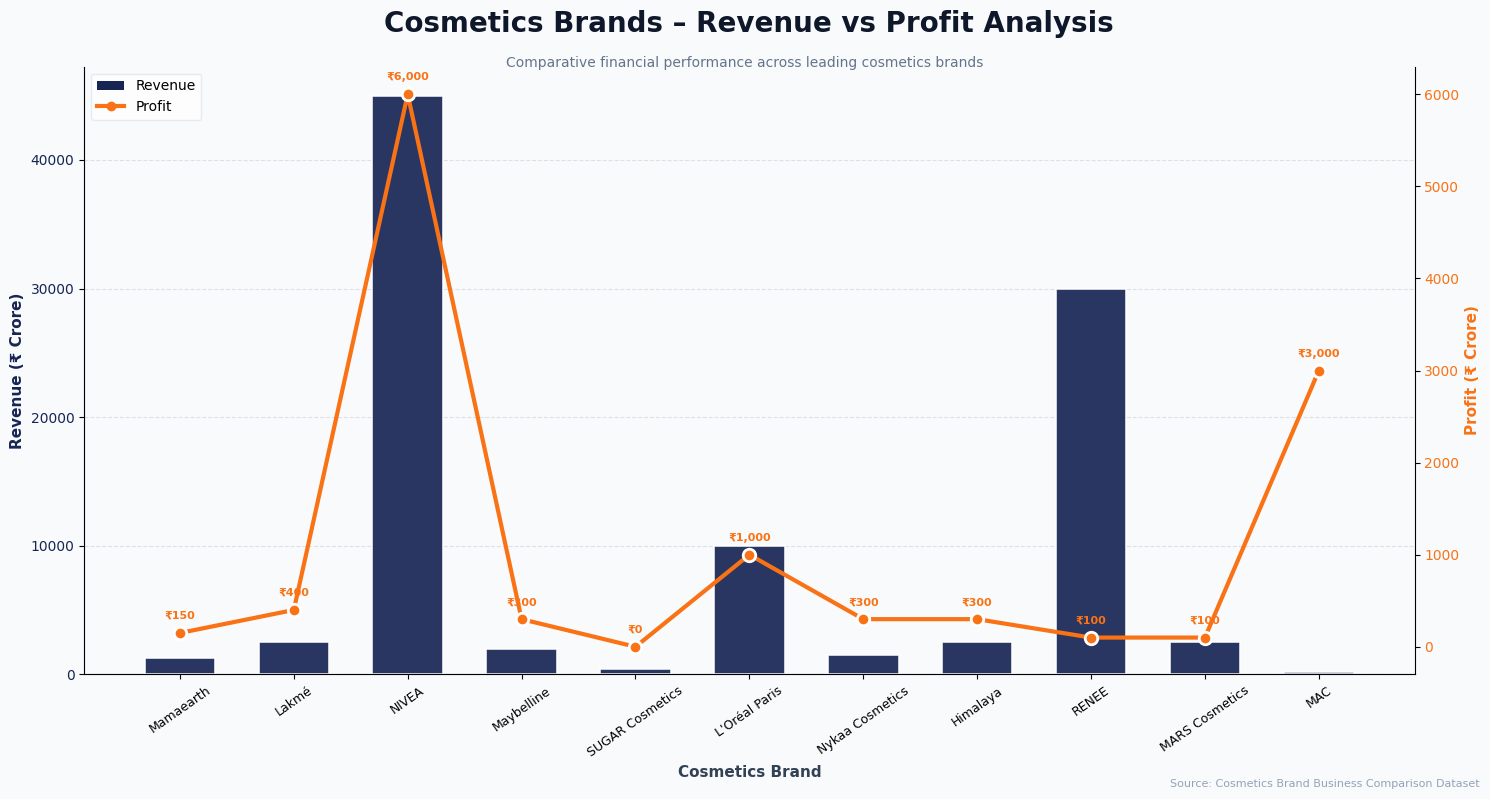

In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

dual_df = df[["Brand", "Revenue (Cr)", "Profit (Cr)"]].copy()

# Professional colour palette
revenue_color = "#172554"   # Deep Navy
profit_color = "#F97316"    # Coral Orange
accent_color = "#0F766E"   # Teal

fig, ax1 = plt.subplots(figsize=(15, 8))
fig.patch.set_facecolor("#F8FAFC")
ax1.set_facecolor("#F8FAFC")

# Revenue bars
bars = ax1.bar(
    dual_df["Brand"],
    dual_df["Revenue (Cr)"],
    width=0.62,
    color=revenue_color,
    alpha=0.92,
    edgecolor="white",
    linewidth=1.2
)

ax1.set_xlabel(
    "Cosmetics Brand",
    fontsize=11,
    fontweight="bold",
    color="#334155"
)

ax1.set_ylabel(
    "Revenue (₹ Crore)",
    fontsize=11,
    fontweight="bold",
    color=revenue_color
)

ax1.tick_params(axis="y", labelcolor=revenue_color)
ax1.tick_params(axis="x", rotation=35, labelsize=9)

# Profit line
ax2 = ax1.twinx()

ax2.plot(
    dual_df["Brand"],
    dual_df["Profit (Cr)"],
    color=profit_color,
    marker="o",
    markersize=9,
    linewidth=3,
    markeredgecolor="white",
    markeredgewidth=2
)

ax2.set_ylabel(
    "Profit (₹ Crore)",
    fontsize=11,
    fontweight="bold",
    color=profit_color
)

ax2.tick_params(axis="y", labelcolor=profit_color)

# Profit labels
for i, value in enumerate(dual_df["Profit (Cr)"]):
    ax2.annotate(
        f"₹{value:,.0f}",
        (i, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
        color=profit_color
    )

# Title
plt.title(
    "Cosmetics Brands – Revenue vs Profit Analysis",
    fontsize=20,
    fontweight="bold",
    color="#0F172A",
    pad=25
)

# Subtitle
fig.text(
    0.5,
    0.91,
    "Comparative financial performance across leading cosmetics brands",
    ha="center",
    fontsize=10,
    color="#64748B"
)

# Grid
ax1.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.18,
    color="#64748B"
)

ax1.set_axisbelow(True)

# Remove unnecessary borders
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#CBD5E1")
ax1.spines["bottom"].set_color("#CBD5E1")

ax2.spines["top"].set_visible(False)

# Professional legend
legend_items = [
    Patch(
        facecolor=revenue_color,
        label="Revenue"
    ),
    Line2D(
        [0],
        [0],
        color=profit_color,
        marker="o",
        linewidth=3,
        label="Profit"
    )
]

ax1.legend(
    handles=legend_items,
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#E2E8F0",
    fontsize=10
)

# Source
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    color="#94A3B8"
)

plt.tight_layout()
plt.show()

In [24]:
df["Derived Expenses (Cr)"] = df["Revenue (Cr)"] - df["Profit (Cr)"]

df[["Brand", "Revenue (Cr)", "Derived Expenses (Cr)", "Profit (Cr)"]].head()

,Brand,Revenue (Cr),Derived Expenses (Cr),Profit (Cr)
0,Mamaearth,1250,1100,150
1,Lakmé,2500,2100,400
2,NIVEA,45000,39000,6000
3,Maybelline,2000,1700,300
4,SUGAR Cosmetics,425,425,0


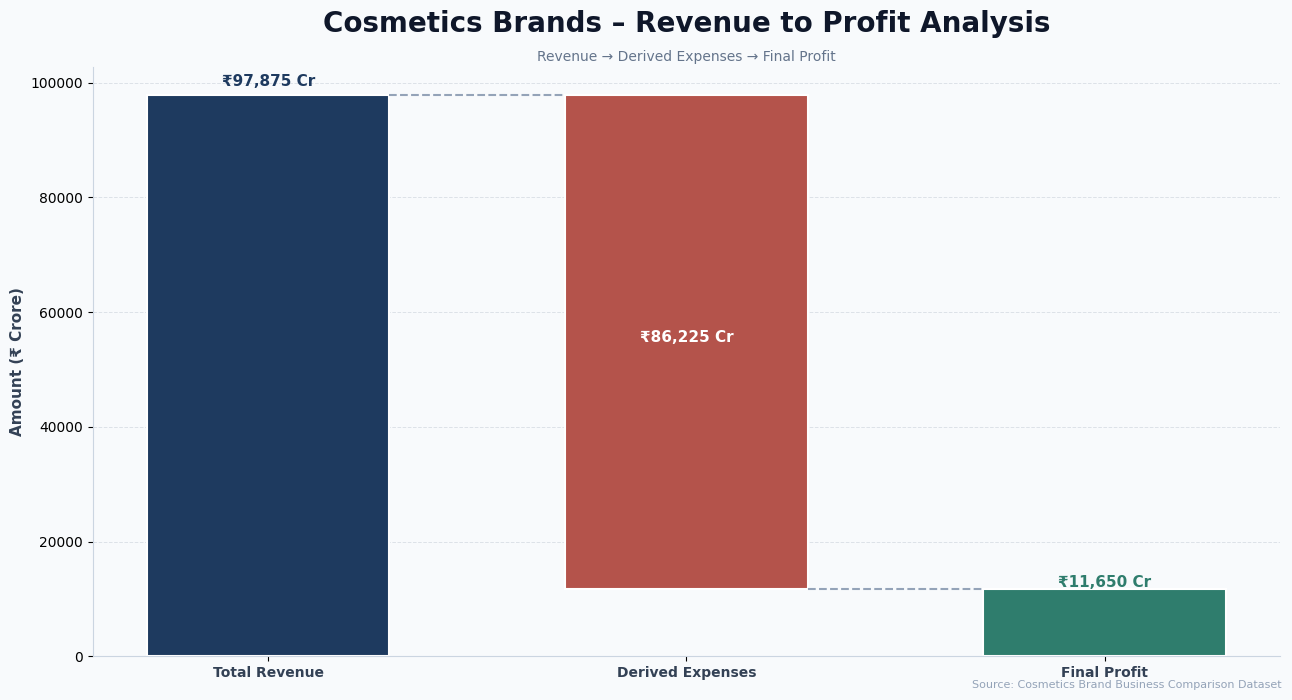

In [26]:
import matplotlib.pyplot as plt

# Values
total_revenue = df["Revenue (Cr)"].sum()
total_expenses = df["Derived Expenses (Cr)"].sum()
total_profit = df["Profit (Cr)"].sum()

# Professional palette
revenue_color = "#1E3A5F"      # Navy
expense_color = "#B4534B"      # Muted Red
profit_color = "#2F7D6D"       # Professional Teal
connector_color = "#94A3B8"    # Soft Grey

fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor("#F8FAFC")
ax.set_facecolor("#F8FAFC")

# ---- BAR 1: REVENUE ----
ax.bar(
    0,
    total_revenue,
    width=0.58,
    color=revenue_color,
    edgecolor="white",
    linewidth=1.5
)

# ---- BAR 2: EXPENSE ----
ax.bar(
    1,
    total_expenses,
    width=0.58,
    bottom=total_profit,
    color=expense_color,
    edgecolor="white",
    linewidth=1.5
)

# ---- BAR 3: PROFIT ----
ax.bar(
    2,
    total_profit,
    width=0.58,
    color=profit_color,
    edgecolor="white",
    linewidth=1.5
)

# Connecting lines
ax.plot(
    [0.29, 0.71],
    [total_revenue, total_revenue],
    color=connector_color,
    linewidth=1.5,
    linestyle="--"
)

ax.plot(
    [1.29, 1.71],
    [total_profit, total_profit],
    color=connector_color,
    linewidth=1.5,
    linestyle="--"
)

# Value labels
ax.text(
    0,
    total_revenue + 1500,
    f"₹{total_revenue:,.0f} Cr",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=revenue_color
)

ax.text(
    1,
    total_profit + total_expenses / 2,
    f"₹{total_expenses:,.0f} Cr",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="white"
)

ax.text(
    2,
    total_profit + 400,
    f"₹{total_profit:,.0f} Cr",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=profit_color
)

# Title
ax.set_title(
    "Cosmetics Brands – Revenue to Profit Analysis",
    fontsize=20,
    fontweight="bold",
    color="#0F172A",
    pad=25
)

# Subtitle
ax.text(
    0.5,
    1.01,
    "Revenue → Derived Expenses → Final Profit",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#64748B"
)

# X-axis
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(
    ["Total Revenue", "Derived Expenses", "Final Profit"],
    fontsize=10,
    fontweight="bold",
    color="#334155"
)

# Y-axis
ax.set_ylabel(
    "Amount (₹ Crore)",
    fontsize=11,
    fontweight="bold",
    color="#334155"
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.18,
    color="#64748B"
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")

# Source
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    color="#94A3B8"
)

plt.tight_layout()
plt.show()

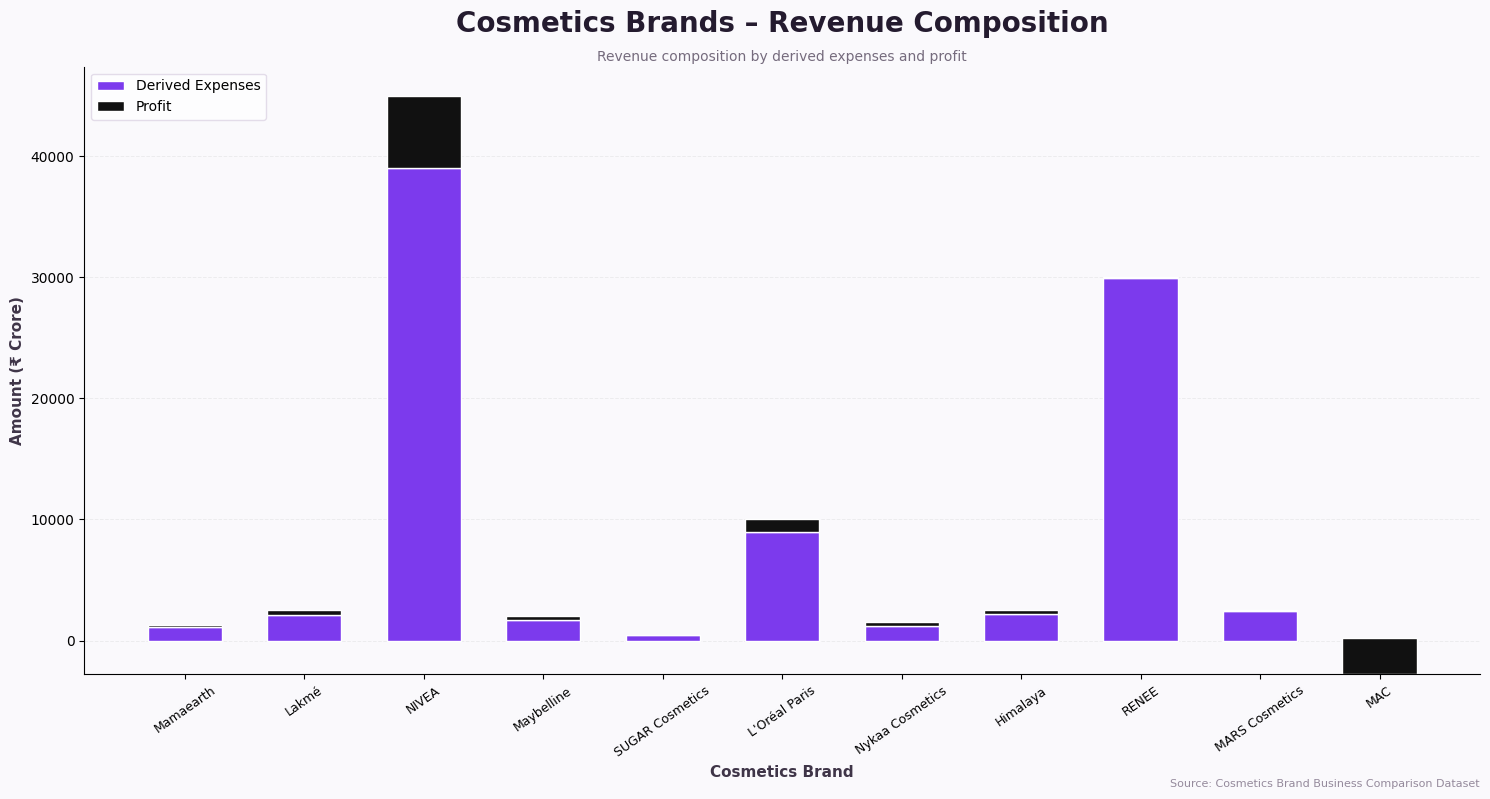

In [36]:
import matplotlib.pyplot as plt

stack_df = df[
    ["Brand", "Derived Expenses (Cr)", "Profit (Cr)"]
].copy()

fig, ax = plt.subplots(figsize=(15, 8))

fig.patch.set_facecolor("#FAF9FC")
ax.set_facecolor("#FAF9FC")

# Premium colour palette
expense_color = "#7C3AED"   # Violet
profit_color = "#111111"     # Black

# Derived Expenses
ax.bar(
    stack_df["Brand"],
    stack_df["Derived Expenses (Cr)"],
    color=expense_color,
    label="Derived Expenses",
    width=0.62,
    edgecolor="white",
    linewidth=1
)

# Profit
ax.bar(
    stack_df["Brand"],
    stack_df["Profit (Cr)"],
    bottom=stack_df["Derived Expenses (Cr)"],
    color=profit_color,
    label="Profit",
    width=0.62,
    edgecolor="white",
    linewidth=1
)

# Title
ax.set_title(
    "Cosmetics Brands – Revenue Composition",
    fontsize=20,
    fontweight="bold",
    color="#241B2F",
    pad=25
)

ax.text(
    0.5,
    1.01,
    "Revenue composition by derived expenses and profit",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#756B7D"
)

ax.set_xlabel(
    "Cosmetics Brand",
    fontsize=11,
    fontweight="bold",
    color="#3F3548"
)

ax.set_ylabel(
    "Amount (₹ Crore)",
    fontsize=11,
    fontweight="bold",
    color="#3F3548"
)

ax.tick_params(
    axis="x",
    rotation=35,
    labelsize=9
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.18
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#DDD5E5",
    fontsize=10
)

# Source
fig.text(
    0.99,
    0.01,
    "Source: Cosmetics Brand Business Comparison Dataset",
    ha="right",
    fontsize=8,
    color="#958A9C"
)

plt.tight_layout()
plt.show()

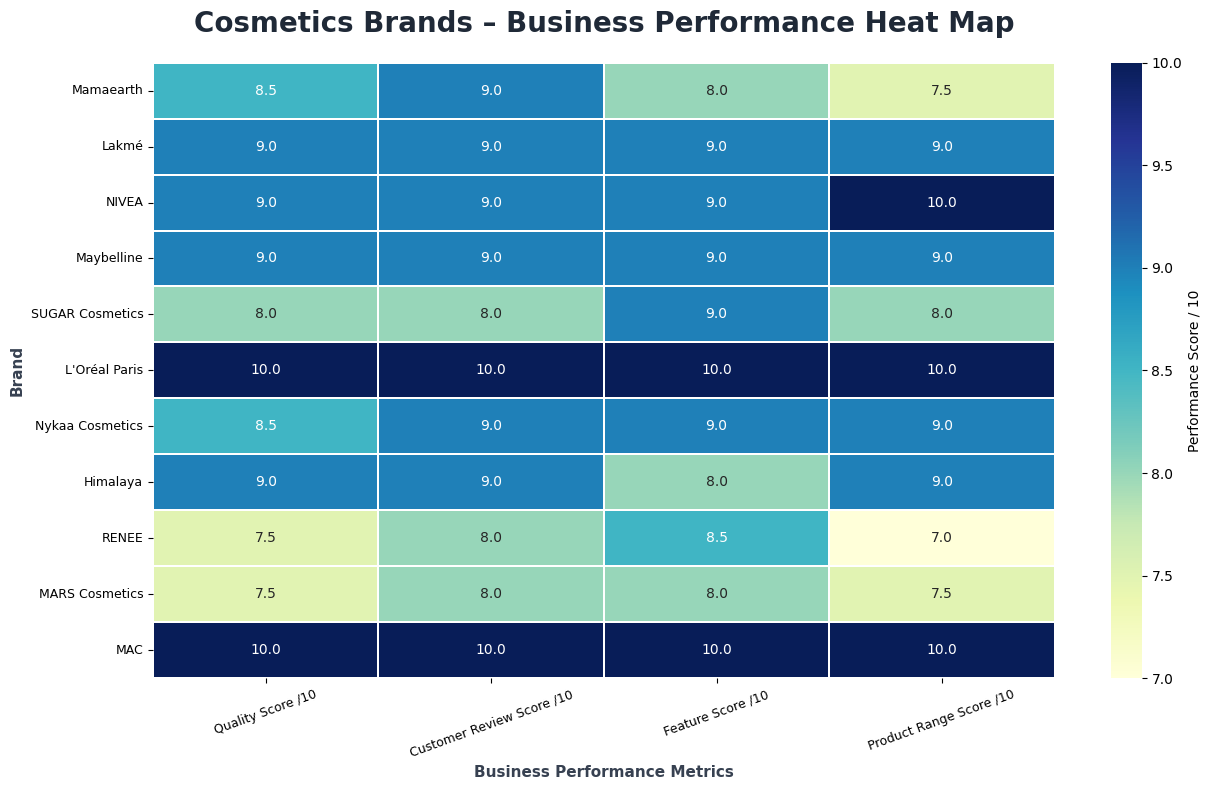

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

heat_df = df[
    [
        "Brand",
        "Quality Score /10",
        "Customer Review Score /10",
        "Feature Score /10",
        "Product Range Score /10"
    ]
].set_index("Brand")

plt.figure(figsize=(13, 8))

sns.heatmap(
    heat_df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=1.2,
    linecolor="white",
    cbar_kws={"label": "Performance Score / 10"}
)

plt.title(
    "Cosmetics Brands – Business Performance Heat Map",
    fontsize=20,
    fontweight="bold",
    color="#1F2937",
    pad=22
)

plt.xlabel(
    "Business Performance Metrics",
    fontsize=11,
    fontweight="bold",
    color="#374151"
)

plt.ylabel(
    "Brand",
    fontsize=11,
    fontweight="bold",
    color="#374151"
)

plt.xticks(
    rotation=20,
    fontsize=9
)

plt.yticks(
    fontsize=9
)

plt.tight_layout()
plt.show()

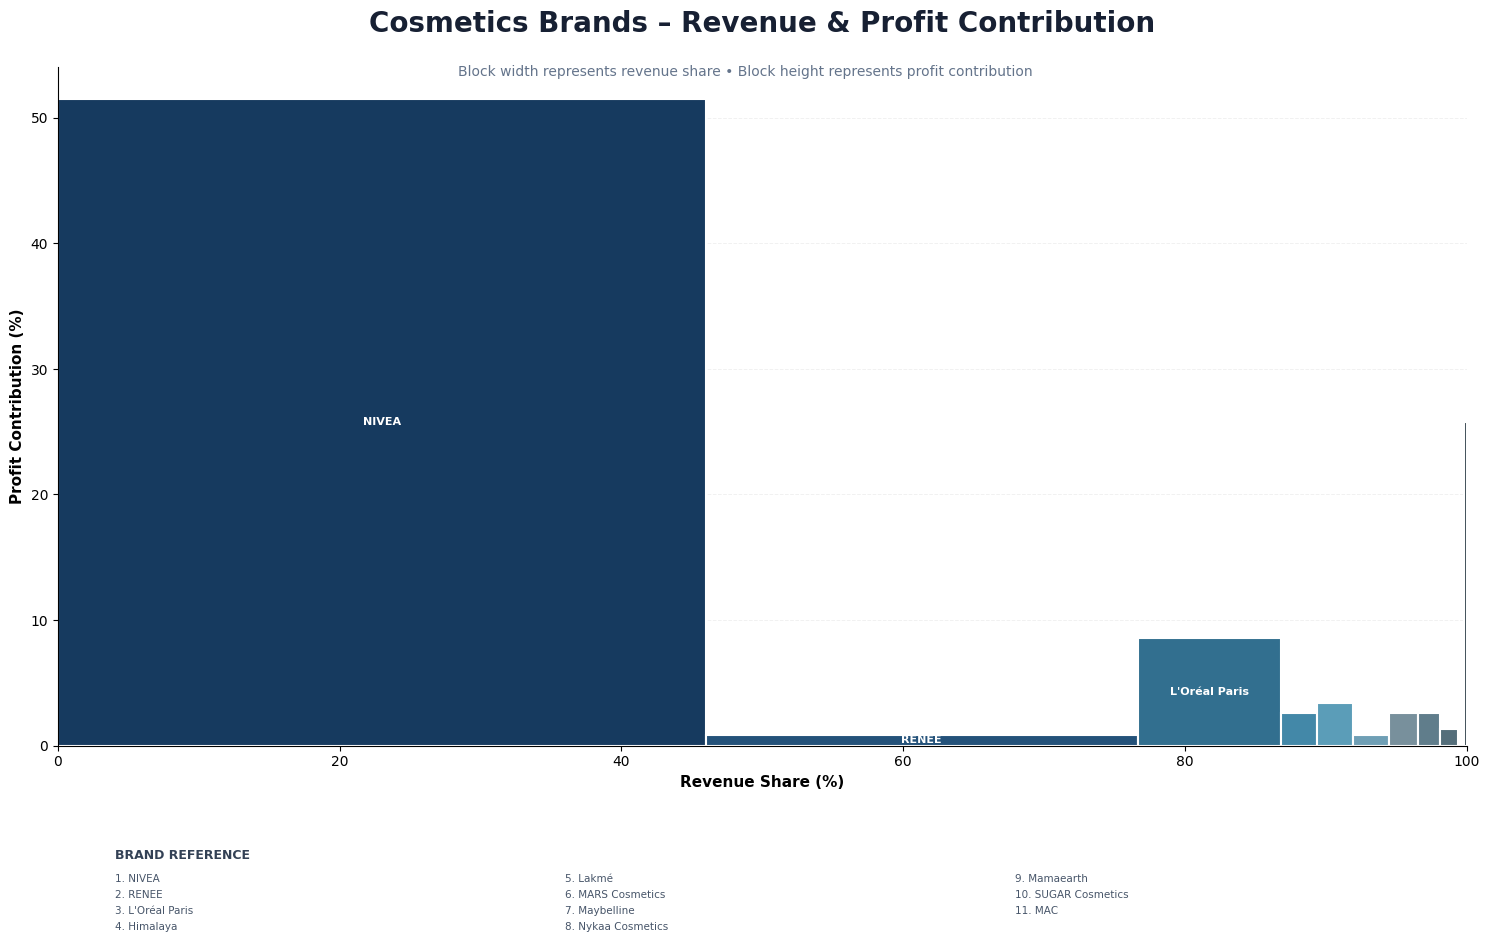

In [41]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

mekko_df = df[
    ["Brand", "Revenue (Cr)", "Profit (Cr)"]
].copy()

# Revenue and profit contribution
mekko_df["Revenue Share (%)"] = (
    mekko_df["Revenue (Cr)"] /
    mekko_df["Revenue (Cr)"].sum() * 100
)

mekko_df["Profit Share (%)"] = (
    mekko_df["Profit (Cr)"] /
    mekko_df["Profit (Cr)"].sum() * 100
)

mekko_df = mekko_df.sort_values(
    "Revenue (Cr)",
    ascending=False
).reset_index(drop=True)

# Professional corporate palette
colors = [
    "#163A5F", "#24527A", "#326F8F",
    "#4388A8", "#5B9DB8", "#6F9FB5",
    "#78909C", "#607D8B", "#546E7A",
    "#455A64", "#37474F"
]

fig, ax = plt.subplots(figsize=(15, 9))

x = 0

for i, row in mekko_df.iterrows():

    width = row["Revenue Share (%)"]
    height = row["Profit Share (%)"]

    ax.bar(
        x + width / 2,
        height,
        width=width,
        color=colors[i],
        edgecolor="white",
        linewidth=1.5
    )

    # Only show labels for sufficiently large blocks
    if width >= 7:
        ax.text(
            x + width / 2,
            height / 2,
            row["Brand"],
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="white"
        )

    x += width


# -------------------------------
# Clean Brand Reference Panel
# -------------------------------

fig.text(
    0.08,
    0.04,
    "BRAND REFERENCE",
    fontsize=9,
    fontweight="bold",
    color="#334155"
)

# Arrange brands in 3 columns
columns = 3
rows = int(np.ceil(len(mekko_df) / columns))

for i, row in mekko_df.iterrows():

    col = i // rows
    r = i % rows

    xpos = 0.08 + col * 0.30
    ypos = 0.015 - r * 0.018

    fig.text(
        xpos,
        ypos,
        f"{i+1}. {row['Brand']}",
        fontsize=7.5,
        color="#475569"
    )


# -------------------------------
# Title
# -------------------------------

ax.set_title(
    "Cosmetics Brands – Revenue & Profit Contribution",
    fontsize=20,
    fontweight="bold",
    color="#172033",
    pad=25
)

fig.text(
    0.5,
    0.91,
    "Block width represents revenue share • Block height represents profit contribution",
    ha="center",
    fontsize=10,
    color="#64748B"
)

ax.set_xlabel(
    "Revenue Share (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Profit Contribution (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_xlim(0, 100)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.18
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.10, 1, 1])

plt.show()

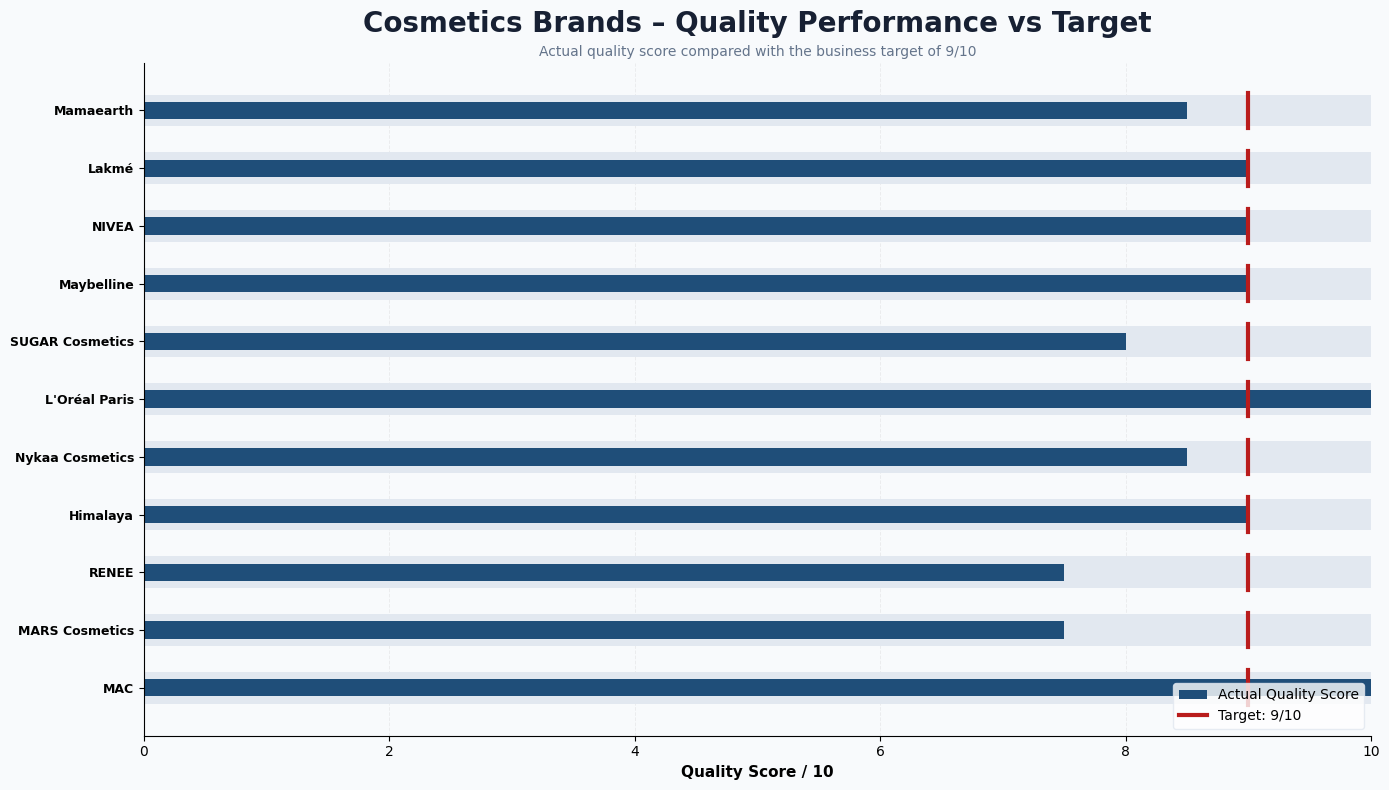

In [42]:
import matplotlib.pyplot as plt
import numpy as np

bullet_df = df[
    ["Brand", "Quality Score /10"]
].copy()

target = 9

fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor("#F8FAFC")
ax.set_facecolor("#F8FAFC")

# Professional colours
actual_color = "#1F4E79"
target_color = "#B91C1C"

y = np.arange(len(bullet_df))

# Background performance ranges
for i in range(len(bullet_df)):
    ax.barh(
        i,
        10,
        color="#E2E8F0",
        height=0.55
    )

# Actual quality score
ax.barh(
    y,
    bullet_df["Quality Score /10"],
    color=actual_color,
    height=0.30,
    label="Quality Score"
)

# Target line
for i in range(len(bullet_df)):
    ax.plot(
        [target, target],
        [i - 0.30, i + 0.30],
        color=target_color,
        linewidth=3
    )

# Brand names
ax.set_yticks(y)
ax.set_yticklabels(
    bullet_df["Brand"],
    fontsize=9,
    fontweight="bold"
)

ax.invert_yaxis()

ax.set_xlim(0, 10)

ax.set_xlabel(
    "Quality Score / 10",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Cosmetics Brands – Quality Performance vs Target",
    fontsize=20,
    fontweight="bold",
    color="#172033",
    pad=22
)

ax.text(
    0.5,
    1.01,
    "Actual quality score compared with the business target of 9/10",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#64748B"
)

# Grid
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.18
)

ax.set_axisbelow(True)

# Remove borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legend_items = [
    Patch(
        facecolor=actual_color,
        label="Actual Quality Score"
    ),
    Line2D(
        [0],
        [0],
        color=target_color,
        linewidth=3,
        label="Target: 9/10"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#E2E8F0"
)

plt.tight_layout()
plt.show()